In [2]:
import numpy as np
import matplotlib.pyplot as plt

In [3]:
# -----------------------------
# distributions & math
# -----------------------------

def trapez_tensor(n: int) -> np.ndarray: #3D-tensor
    """
    Compute trapezoid distribution tensor T[k,y1,y2].
    Each slice T[:, y1, y2] gives P(k | y1,y2).
    """
    K  = np.arange(1, n + 1)[:, None, None]  # shape (n,1,1)
    Y1 = np.arange(1, n + 1)[None, :, None]  # (1,n,1)
    Y2 = np.arange(1, n + 1)[None, None, :]  # (1,1,n)

    ysum = Y1 + Y2
    ymin = np.minimum(Y1, Y2)
    ymax = np.maximum(Y1, Y2)

    # valid range
    valid = (K <= (ysum - 1))

    # main value using vectorized where
    val = np.where(K <= ymin, K,                # case A
          np.where(K <= ymax, ymin,             # case B
          np.where(valid, ysum - K, 0.0)))      # case C and invalid

    # normalize by y1*y2, zero out invalid
    denom = (Y1 * Y2).astype(float)
    T = np.where(valid, val / denom, 0.0)
    return T



def f_post_neutral(f_prior: np.ndarray, r: float, T: np.ndarray) -> np.ndarray:
    """
    One-generation update under neutrality.

    f_post(k) = (1 - r) * f_prior(k) + r * sum_{y1,y2} f(y1) f(y2) T[k, y1, y2]

    - Exploits the identity that the no-recombination part collapses to (1-r) * f.
    - Recombinant part is an einsum over the precomputed kernel T.

    Inputs:
      f_prior: shape (n,), probabilities over y=1..n
      r: recombination probability
      T: shape (n,n,n) = trapez_tensor(n)
    """
    f_prior = f_prior.astype(float)
    f_prior /= f_prior.sum()

    # recombinant mixture: r * sum_{y1,y2} f(y1) f(y2) T[k,y1,y2]
    recomb = np.einsum('kij,i,j->k', T, f_prior, f_prior, optimize=True)

    f_post = (1.0 - r) * f_prior + r * recomb
    # renormalize (in case you truncate the support to 1..n)
    f_post /= f_post.sum()
    return f_post


def stationary_theory_from_mean(E0: float, n: int) -> np.ndarray:
    """
    The neutral pseudo-equilibrium (given initial mean E0):
      P(y) ∝ y * exp(-2y / E0), for y = 1..n
    """
    y = np.arange(1, n + 1, dtype=float)
    p = y * np.exp(-2.0 * y / E0)
    p /= p.sum()
    return p


def iterate_until_convergence(f0: np.ndarray, r: float, T: np.ndarray,
                              tol: float = 1e-8, max_iter: int = 10000):
    """
    Iterate f_post under neutrality until L1 difference < tol or max_iter hit.
    Returns (f, iters, converged: bool).
    """
    f = f0 / f0.sum()
    for it in range(1, max_iter + 1):
        f_new = f_post_neutral(f, r, T)
        diff = np.abs(f_new - f).sum()
        f = f_new
        if diff < tol:
            return f, it, True
    return f, max_iter, False


In [4]:
# -----------------------------
# Demo usage
# -----------------------------
if __name__ == "__main__":
    # Model size and recombination
    n = 100
    r_list = [0.01, 0.05, 0.1]

    # Precompute trapezoid kernel once
    T = trapez_tensor(n)

    # Initial distribution: a Gaussian-shaped prior around 10
    y = np.arange(1, n + 1)
    f0 = np.exp(-((y - 10.0) ** 2) / (2.0 * 3.0 ** 2))
    f0 /= f0.sum()

    # Theoretical neutral "stationary" given initial mean
    E0 = (y * f0).sum()
    f_theory = stationary_theory_from_mean(E0, n)


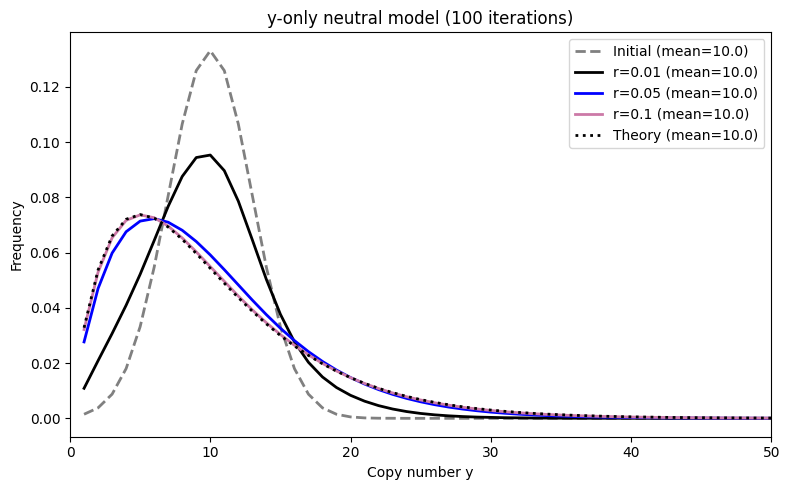

In [13]:


if __name__ == "__main__":
    n = 200
    y = np.arange(1, n + 1)
    T = trapez_tensor(n)

    # Initial distribution
    f0 = np.exp(-((y - 10.0) ** 2) / (2 * 3.0 ** 2))
    f0 /= f0.sum()

    # Initial mean and theory
    E0 = np.sum(y * f0)
    f_theory = stationary_theory_from_mean(E0, n)

    # Recombination rates to compare
    r_list = [0.01, 0.05, 0.1]
    colors = ["black", "blue", "#CC79A7"]

    # Fixed iteration setting used in iterate_until_convergence
    max_iter = 100

    plt.figure(figsize=(8, 5))

    # Initial state
    mean0 = np.sum(y * f0)
    plt.plot(
        y, f0,
        color="gray",
        linestyle="--",
        linewidth=2,
        label=f"Initial (mean={mean0:.1f})"
    )

    # Converged/final states for different r
    for r, col in zip(r_list, colors):
        f_conv, iters, ok = iterate_until_convergence(
            f0, r, T, tol=1e-10, max_iter=max_iter
        )

        mean = np.sum(y * f_conv)

        plt.plot(
            y, f_conv,
            color=col,
            linestyle="-",
            linewidth=2,
            label=f"r={r} (mean={mean:.1f})"
        )

    # Theory
    mean_th = np.sum(y * f_theory)
    plt.plot(
        y, f_theory,
        color="black",
        linestyle=":",
        linewidth=2,
        label=f"Theory (mean={mean_th:.1f})"
    )

    plt.xlabel("Copy number y")
    plt.ylabel("Frequency")
    plt.title(f"y-only neutral model ({max_iter} iterations)")
    plt.legend()
    plt.xlim(0, 50)
    plt.tight_layout()
    plt.savefig("D0_neutral_model.png", dpi=300, bbox_inches="tight")
    plt.show()
